# Part 4: Which request goes first? (shortest prompt first, with aging)

Fill the Part 4 TODOs in `vidur/scheduler/replica_scheduler/spf_replica_scheduler.py` first (`pytest tests/test_spf.py`). Then run SPF at five aging values, from the repo root:

```bash
for A in 0 25 50 100 200; do
  SCHED=spf CHUNK=512 AGING=$A QPS=5.53 bash scripts/run_default.sh traces/azure_conversation.csv
done
```

Runs go one after another, about 3 minutes each. If you have plenty of RAM, you can run them in the background instead (add `&` after each command, then `wait`), but each run needs a few GB: four at once ran out of memory on a 16 GB laptop.

Compare them with your Part 3 Sarathi run at C = 512, which starts requests in arrival order.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.replay import describe_run, load_run
from analysis.workload import load_trace

SURGE = (1350, 2230)   # seconds of trace time where one GPU falls behind (Parts 1-3)

trace = load_trace(ROOT / "traces" / "azure_conversation.csv")

# Your Part 3 Sarathi C=512 run and your five SPF runs, any order.
RUN_DIRS = [ROOT / "simulator_output" / d for d in [
    "2026-10-25_18-46-38-069761",
    "2026-10-25_21-37-00-814998", "2026-10-25_21-38-17-877938", "2026-10-25_21-39-38-162547", "2026-10-25_21-40-55-881828", "2026-10-25_21-42-16-707885",
]]
def _order(name):  # arrival order first, then by aging
    return float(name.split("aging=")[1]) if "aging=" in name else -1.0

runs = {describe_run(d): load_run(d, trace)["requests"] for d in RUN_DIRS}
runs = dict(sorted(runs.items(), key=lambda kv: _order(kv[0])))
print(list(runs))

['sarathi C=512', 'spf C=512 aging=0', 'spf C=512 aging=25', 'spf C=512 aging=50', 'spf C=512 aging=100', 'spf C=512 aging=200']


## Median vs worst case

run                         surge median      P99     worst   over 3 min
sarathi C=512                    112.2 s  171.2 s   175.2 s            0
spf C=512 aging=0                  0.2 s  647.8 s  1482.5 s          383
spf C=512 aging=25                38.3 s  212.5 s   258.7 s          425
spf C=512 aging=50                78.4 s  181.1 s   211.7 s          202
spf C=512 aging=100               96.7 s  168.9 s   190.5 s           84
spf C=512 aging=200              105.5 s  166.2 s   182.1 s           27


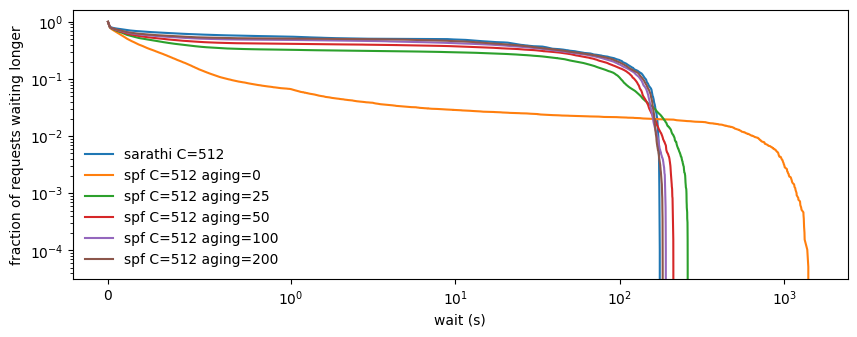

In [2]:
print(f"{'run':26s}{'surge median':>14s}{'P99':>9s}{'worst':>10s}{'over 3 min':>13s}")
for name, req in runs.items():
    surge = req[(req.arrived_at >= SURGE[0]) & (req.arrived_at <= SURGE[1])]
    print(f"{name:26s}{surge.wait.median():12.1f} s{req.wait.quantile(.99):7.1f} s"
          f"{req.wait.max():8.1f} s{int((req.wait > 180).sum()):13d}")

fig, ax = plt.subplots(figsize=(10, 3.5))
for name, req in runs.items():
    xs = np.sort(req.wait.to_numpy())
    ax.plot(xs, 1 - np.arange(1, len(xs) + 1) / len(xs), label=name)
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("log")
ax.set_xlabel("wait (s)")
ax.set_ylabel("fraction of requests waiting longer")
ax.legend(frameon=False)
plt.show()

## Who waits longest under shortest-prompt-first?

In [3]:
spf = next(req for name, req in runs.items() if name.endswith("aging=0"))
print(spf.sort_values("wait", ascending=False)
      .head(8)[["arrived_at", "num_prefill_tokens", "num_decode_tokens", "wait"]]
      .round(1).to_string(index=False))

 arrived_at  num_prefill_tokens  num_decode_tokens   wait
     1344.0                4071                 25 1482.5
     1429.8                4071                 25 1397.2
     1346.4                4069                 27 1377.0
     1403.1                4069                 27 1327.6
     1495.7                4070                 26 1324.0
     1415.0                4069                 27 1316.9
     1428.2                4069                 27 1313.7
     1351.1                4068                 28 1311.5


## Questions

**Q1.** Fill in the table. The surge is the requests that arrive between t = 1350 s and t = 2230 s. Which order gives the lowest surge median wait, and which gives the lowest worst wait? Does any order meet the 2 s P99 target?

| Order | Surge median wait | P99 wait | Worst wait | Requests waiting over 3 min |
|---|---|---|---|---|
| Arrival order (Part 3) |112.2 s|171.2 s |175.2 s | 0|
| Aging 0 (plain shortest-first) | 0.2 s|647.8 s| 1482.5 s|383 |
| Aging 25 | 38.3 s|212.5 s|258.7 s|425 |
| Aging 50 | 78.4 s|181.1 s|211.7 s|202 |
| Aging 100 | 96.7 s|168.9 s|190.5 s| 84|
| Aging 200 | 105.5 s|166.2 s| 182.1 s| 27|

**Your answer:**
The lowest surge meidan wait is (spf C=512 aging=0). The lowest worst wait is (sarathi C=512). No order meet the 2 s P99 target.

**Q2.** Under shortest-prompt-first (aging 0), how long are the prompts of the requests that wait longest, and when did they arrive? In one sentence, why do they wait so long? P99 is a wait that only 1% of requests (194 of 19,366) exceed. Compare each order's count of requests waiting over 3 min with 194: what does it tell you about aging 0's P99 versus arrival order's?

**Your answer:**
The prompts of the request that wait longest is 4071 tokens long and arrived at 1334.0 t=s. The reason why it wait so long was because it the longest prompt (most number of tokens) while using shortest first queuing and arrived shortly before the surge period causing this request to be starve.

Aging 0's count of rquests waiting over 3 min is 425 which is significantly greater than 194 and this is reflected with the significantly higher P99 waiting timee of 647.8s versus 180 second (3 minute).

**Q3.** From your table: does any aging beat arrival order on both P99 and worst wait? Against plain SPF, what does aging improve, and what does it cost in surge median wait? In one or two sentences: when does aging reduce starvation here, and when does it not help?

**Your answer:**

Based on my table, no form of aging beat arrival order on both P99 and worst wait. When using plain SPF, aging greatly imporve the surge median wait but at the cost of P99 wait, the worst wait, and increase number of significantly long (> 3 min) waiting requests.

Aging reduces starvation by allowing long prompt's to overtake shorter prompts, which arrived behind it, before the surge ends and allowing hte long prompt requst to be processed. However, aging does not help if the aging value is too small and weak causing long prompts needing to wait a significantly amount of time to overtake shorter prompt.